In [30]:
import networkx as nx
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import operator

# Data preproccess

In [2]:
G_all =nx.readwrite.gexf.read_gexf('viz/all.gexf')
G_sub =nx.readwrite.gexf.read_gexf('viz/sub.gexf')
comps = nx.algorithms.components.connected_components(G_sub)
S = [G_sub.subgraph(c).copy() for c in nx.connected_components(G_sub)]
G_sub1 = S[0]
degree_dict =dict( G_sub1.degree)


sorted_degree = sorted(degree_dict.items(), key=operator.itemgetter(1))
df_dg = pd.DataFrame({'account':degree_dict.keys(),"degree":degree_dict.values()})
df_dg['group'] = df_dg.account.apply(lambda x: G_sub.nodes[x]['group'])
name_gp_dict = dict(zip(df_dg['account'],df_dg['group']))

# Degree report

Degree of a node is a measure of how many connections it has in the network.
Here you can see the overall degree statistics and also the nodes with top degree in each groups.

In [51]:
df_dg.groupby('group').mean()[['degree']].round(0).reset_index().rename(columns={'degree':'avg_degree'})

,group,avg_degree
0,right,26.0
1,tagged hate,24.0


In [52]:
df_dg[df_dg['group']=='right'].sort_values('degree',ascending =False).head(10)

,account,degree,group
150,SBCPastorsConf,133,right
59,RepMarkGreen,106,right
175,CongressmanHice,96,right
100,FRCdc,92,right
21,SenatorLankford,88,right
99,ericmetaxas,87,right
67,Franklin_Graham,83,right
158,RepHartzler,81,right
101,ACLJ,80,right
0,SteveScalise,74,right


In [53]:
df_dg[df_dg['group']!='right'].sort_values('degree',ascending =False).head(10)

,account,degree,group
129,KyleBristow,80,tagged hate
113,vdare,67,tagged hate
116,identitydixie1,60,tagged hate
57,JamesEdwardsTPC,56,tagged hate
130,ProudBoysUS,45,tagged hate
180,RenaissanceHor1,34,tagged hate
29,NatReformation,20,tagged hate
14,LeagueOfSouth,20,tagged hate
122,antelopehill,20,tagged hate
176,amsance2015,13,tagged hate


# Direct connection
### Right follow hate

In [ ]:
right_follow_hate = [('toddstarnes', 'vdare'),
('toddstarnes', 'peterbrimelow'),
('RepMarkWalker', 'identitydixie1'),
('RepMarkWalker', 'NewRightAmerica'),
('RepMarkWalker', 'vdare'),
('RepMarkWalker', 'peterbrimelow'),
('RepMarkWalker', 'NationVanguard'),
('CBNNews', 'vdare'),
('AmericanFamAssc', 'identitydixie1'),
('AmericanFamAssc', 'vdare'),
('AmericanFamAssc', 'NewRightAmerica'),
('AmericanFamAssc', 'peterbrimelow'),
('kenblackwell', 'JamesEdwardsTPC'),
('kenblackwell', 'NewRightAmerica'),
('kenblackwell', 'vdare'),
('GregBaylor', 'JamesEdwardsTPC'),
('GregBaylor', 'peterbrimelow'),
('GregBaylor', 'vdare'),
('MarkMartinCBN', 'identitydixie1'),
('MarkMartinCBN', 'JamesEdwardsTPC'),
('MarkMartinCBN', 'NewRightAmerica'),
('MarkMartinCBN', 'peterbrimelow'),
('RealBenCarson', 'peterbrimelow'),
('RealBenCarson', 'vdare')]
edge_list = list(G_sub.edges)
hate_follow_right = [eg for eg in edge_list 
                     if (eg not in right_follow_hate)and
                    (eg[::-1] not in right_follow_hate)and
                    (G_sub.nodes[eg[0]]['group']!=G_sub.nodes[eg[1]]['group'])]
hate_follow_right = [eg if G_sub.nodes[eg[0]]['group']=='tagged hate' else eg[::-1]
                     for eg in hate_follow_right ]

In [68]:
print("These right accounts are following hate accounts:")
print(np.array(right_follow_hate)[:,0])

These right accounts are following hate accounts:
['toddstarnes' 'toddstarnes' 'RepMarkWalker' 'RepMarkWalker'
 'RepMarkWalker' 'RepMarkWalker' 'RepMarkWalker' 'CBNNews'
 'AmericanFamAssc' 'AmericanFamAssc' 'AmericanFamAssc' 'AmericanFamAssc'
 'kenblackwell' 'kenblackwell' 'kenblackwell' 'GregBaylor' 'GregBaylor'
 'GregBaylor' 'MarkMartinCBN' 'MarkMartinCBN' 'MarkMartinCBN'
 'MarkMartinCBN' 'RealBenCarson' 'RealBenCarson']


### Hate follow right

['FRCdc' 'KellyannePolls' 'michellemalkin' 'Franklin_Graham' 'Mike_Pence'
 'LilaGraceRose' 'newtgingrich' 'MarkMeadows' 'tperkins' 'SebGorka'
 'SarahPalinUSA' 'SenatorLankford' 'GenBoykin' 'conservmillen'
 'ericmetaxas' 'SenatorTimScott' 'AllenWest' 'Reince' 'MittRomney'
 'SteveScalise' 'HawleyMO' 'MarshaBlackburn' 'FocusFamily' 'MeghanMcCain'
 'albertmohler' 'ACLJ' 'DennisPrager' 'MicheleBachmann' 'RedState'
 'RickSantorum' 'CarlyFiorina' 'AlvedaCKing' 'JaySekulow' 'mikepompeo'
 'replouiegohmert' 'toddstarnes' 'AllianceDefends' 'RepMarkGreen' 'CWforA'
 'RepAnnWagner' 'DrJamesCDobson' 'CongressmanHice' 'JerryFalwellJr'
 'AbbyJohnson' 'DavidBrodyCBN' 'marjoriesba' 'DalyFocus' 'DavidAFrench'
 'RealBenCarson' 'BenjaminSWatson' 'JenniferWishon' 'JohnJessupCBN'
 'PYNance' 'Jeff_Iorg' 'JCNSeverino' 'PaulStrandCBN' 'McCormickProf'
 'wendygcbn' 'OliverLNorth' 'RealDeanCain' '700club' 'jonvoight'
 'michaeljohns' 'SBCLIFE' 'SBCthisWeek' 'RepMarkWalker' '7CInteractive'
 'rangerholton' 'EfremGraha

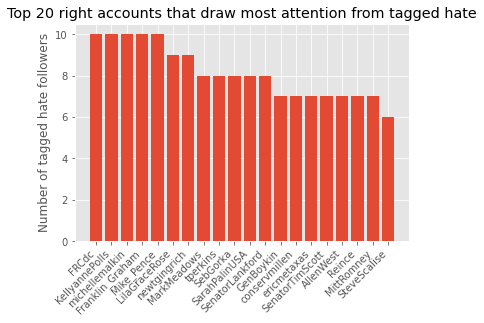

In [69]:
ct_r = np.unique(np.array(hate_follow_right)[:,1],return_counts=True)
idx = np.argsort(ct_r[1])[::-1]
print(ct_r[0][idx])
print(ct_r[1][idx])
plt.style.use('ggplot')
k = 20
x = ct_r[0][idx][:k]
energy = ct_r[1][idx][:k]
x_pos = list(range(len(x)))
plt.bar(x_pos, 
        energy)

plt.ylabel("Number of tagged hate followers")
# plt.xlabel("Top k")
plt.title("Top %d right accounts that draw most attention from tagged hate"%k)

plt.xticks(x_pos, x,rotation = 45,ha='right')
# plt.legend()
plt.savefig("plot/top_right_by_hate.pdf",bbox_inches='tight')
plt.show()

# Indirect connection
### hate-right Pair Distance

In [70]:
name_right_net = df_dg[df_dg.group=='right'].account.values
name_tag_net = df_dg[df_dg.group!='right'].account.values
right_tag_pair = [(right,tag) for right in name_right_net for tag in name_tag_net]
pair_dist =[]
for pair in right_tag_pair:
    pair_dist.append(len(nx.algorithms.shortest_paths.generic.shortest_path(G_sub,pair[0],pair[1]))-1)

In [71]:
pair_dist =[]
for pair in right_tag_pair:
    pair_dist.append(len(nx.algorithms.shortest_paths.generic.shortest_path(G_all,pair[0],pair[1]))-1)

avg dist:  2.1118493909191582
percentage of less than 2 steps:  0.7267441860465116


/Users/luocan/opt/anaconda3/lib/python3.8/site-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


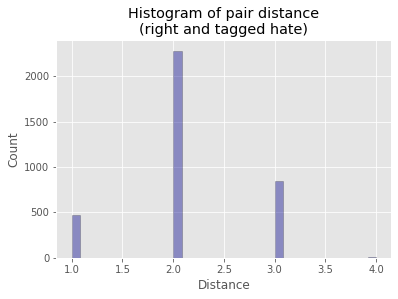

In [72]:
sns.distplot(pair_dist, hist=True, kde=False, 
             bins=int(180/5), color = 'darkblue', 
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 4},
          )
# Add labels
plt.title('Histogram of pair distance\n(right and tagged hate)')
plt.ylabel('Count')
plt.xlabel('Distance')
print("avg dist: ",sum(pair_dist)/len(pair_dist))
print("percentage of less than 2 steps: ",(469+2156)/len(pair_dist))

### right-right pair distance

avg distance:  1.9647082823337414
distance distribution: (array([1, 2, 3, 4]), array([ 1996, 11245,  1453,    12]))
percentge of less than 2 steps:  0.9003807969536244


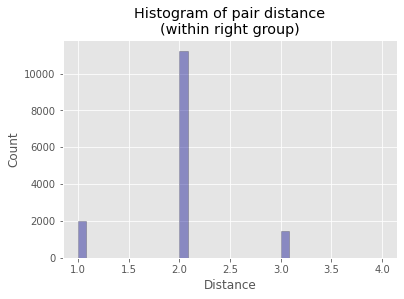

In [97]:

right_right_pair = [(right1,right2) for right1 in name_right_net for right2 in name_right_net if right1>right2]
pair_dist_rr =[]
for pair in right_right_pair:
    pair_dist_rr.append(len(nx.algorithms.shortest_paths.generic.shortest_path(G_all,pair[0],pair[1]))-1)
    
sns.distplot(pair_dist_rr, hist=True, kde=False, 
             bins=int(180/5), color = 'darkblue', 
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 4},
          )
# Add labels
plt.title('Histogram of pair distance\n(within right group)')
plt.ylabel('Count')
plt.xlabel('Distance')

print("avg distance: ",sum(pair_dist_rr)/len(pair_dist_rr))
ct_rr = np.unique(pair_dist_rr,return_counts = True)
print("distance distribution:",ct_rr)
print("percentge of less than 2 steps: ",ct_rr[1][:2].sum()/len(pair_dist_rr))


## hate-hate pair distance

how many linkage:  210
avg distance:  2.2476190476190476
distance distribution: (array([1, 2, 3]), array([ 11, 136,  63]))
percentge of less than 2 steps:  0.7


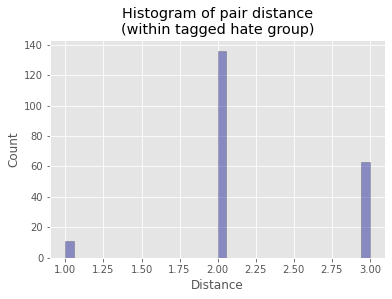

In [96]:

right_right_pair = [(right1,right2) for right1 in name_tag_net for right2 in name_tag_net if right1>right2]
print("how many linkage: ",len(right_right_pair))
pair_dist_rr =[]
for pair in right_right_pair:
    pair_dist_rr.append(len(nx.algorithms.shortest_paths.generic.shortest_path(G_sub,pair[0],pair[1]))-1)
    
sns.distplot(pair_dist_rr, hist=True, kde=False, 
             bins=int(180/5), color = 'darkblue', 
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 4},
          )
# Add labels
plt.title('Histogram of pair distance\n(within tagged hate group)')
plt.ylabel('Count')
plt.xlabel('Distance')

print("avg distance: ",sum(pair_dist_rr)/len(pair_dist_rr))
ct_rr = np.unique(pair_dist_rr,return_counts = True)
print("distance distribution:",ct_rr)
print("percentge of less than 2 steps: ",ct_rr[1][:2].sum()/len(pair_dist_rr))


### Bridge nodes

In [81]:
import pandas as pd
import json
f = open("data/user_profile/users.json",'r')
s = f.read().split('\n')[:-1]
row_list = []

for line in s:
    prof = json.loads(line)
    row =[]
    headers = ['id', 'screen_name','location',"description", "followers_count", "followers_count",
               'friends_count', "listed_count", "favourites_count", "created_at"]
    for header in headers:
        row.append(prof[header])
    row_list.append(row)
    
df_loc = pd.DataFrame(row_list,columns = headers)
df_loc["og_name"] = list(G_all.nodes)[:201]+list(G_all.nodes)[202:]
degree_dict =dict( G_all.degree)
sorted_degree = sorted(degree_dict.items(), key=operator.itemgetter(1))
df_dg = pd.DataFrame({'account':degree_dict.keys(),"degree":degree_dict.values()})
df_dg['group'] = df_dg.account.apply(lambda x: G_all.nodes[x]['group'])
name_gp_dict = dict(zip(df_dg['account'],df_dg['group']))
df_loc['group'] = df_loc.og_name.apply(lambda x: name_gp_dict[x])

In [93]:
pair_path =[]
for pair in right_tag_pair:
    pair_path.extend(nx.algorithms.shortest_paths.generic.shortest_path(G_sub,pair[0],pair[1])[1:-1])
    
bridge_ct = np.unique(pair_path,return_counts = True)
idx = np.argsort(bridge_ct[1])[::-1]
bridge_sort = bridge_ct[0][idx]
df_bridge = pd.DataFrame({'screen_name':bridge_sort,'count':bridge_ct[1][idx]})
df_bridge = df_bridge.merge(df_loc)

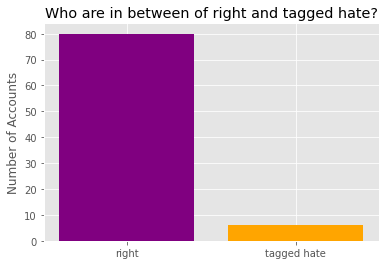

# of accounts from hate:  80
# of accounts from tagged hate:  6
Total accounts:  86


In [94]:

plt.style.use('ggplot')
k =df_bridge.shape[0]
color_dict = {'right':'purple','tagged hate':'green'}
color_list = df_bridge.head(k).group.map(color_dict)

ct = np.unique(df_bridge.group,return_counts = True)

x = ct[0]
energy = ct[1]
x_pos = np.array(list(range(len(x))))
plt.bar(x_pos, 
        energy,
       
       color = ['purple','orange'])

plt.ylabel("Number of Accounts")
# plt.xlabel("Top k")
plt.title("Who are in between of right and tagged hate?")

plt.xticks(x_pos, x)
# plt.legend()
plt.savefig("plot/bridge_cat.pdf")
plt.show()
print("# of accounts from hate: ",ct[1][0])
# print("# of accounts from right: ",ct[1][1])
print("# of accounts from tagged hate: ",ct[1][1])
print("Total accounts: ",sum(ct[1]))

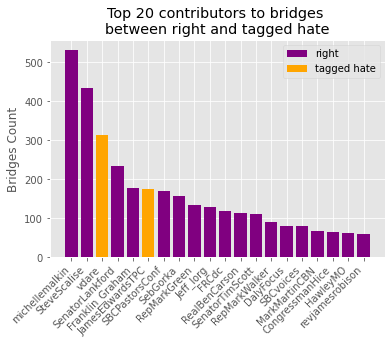

percentage of people:  0.23255813953488372
percentage of bridges:  0.8010167029774873


In [98]:

plt.style.use('ggplot')
k =20
color_dict = {'right':'purple','tagged hate':'orange'}
color_list = df_bridge.head(k).group.map(color_dict)
x = df_bridge.head(k).screen_name
energy = df_bridge.head(k)['count']
x_pos = np.array(list(range(k)))
label_list = list(color_dict.keys())
for i in range(len(label_list)):
    plt.bar( 
        x_pos[df_bridge.head(k).group==label_list[i]], 
        energy[df_bridge.head(k).group==label_list[i]],
        label = label_list[i],
           color = color_dict[label_list[i]])

plt.ylabel("Bridges Count")
# plt.xlabel("Top k")
plt.title("Top %d contributors to bridges \nbetween right and tagged hate"%k)

plt.xticks(x_pos, x,rotation = 45,ha = 'right')
plt.legend()
plt.savefig("plot/bridge.pdf",bbox_inches='tight')
plt.show()
sum_topk = df_bridge['count'][:k].sum()
sum_all = df_bridge['count'].sum()
print("percentage of people: ",k/ df_bridge.shape[0])
print("percentage of bridges: ",sum_topk/sum_all)

In [101]:
# df_loc.to_csv("data/df_loc.csv",index=False)